# Introduction

The goal of this project is to analyze the automotive dataset to extract insight and to give a complete summary.

### Business Objectives

- Identify price drivers : understand which technical features significantly influence a vehicle's market value.
- Evaluate fuel efficency : analyze the trade-off between engine performance and fuel consumption.
- Analyze brand positioning : understand the market strategies of different manufacturers in terms of price ranges and body styles offered.

In [65]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

## Data Cleaning and Processing

In [66]:
# General overview of the dataset

data = pd.read_csv("data/automobile.csv")
df = pd.DataFrame(data)
df.columns = df.columns.str.lower().str.strip().str.replace('-','_')
df.head()
df.describe()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 202 entries, 0 to 201
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          202 non-null    int64  
 1   normalized_losses  165 non-null    float64
 2   make               202 non-null    str    
 3   fuel_type          202 non-null    str    
 4   aspiration         202 non-null    str    
 5   num_of_doors       200 non-null    str    
 6   body_style         202 non-null    str    
 7   drive_wheels       202 non-null    str    
 8   engine_location    202 non-null    str    
 9   wheel_base         202 non-null    float64
 10  length             202 non-null    float64
 11  width              202 non-null    float64
 12  height             202 non-null    float64
 13  curb_weight        202 non-null    int64  
 14  engine_type        202 non-null    str    
 15  num_of_cylinders   202 non-null    str    
 16  engine_size        202 non-null    in

Columns:

1. symboling: The assigned insurance risk rating of the vehicle. Integer values ranging from -3 to +3. A value of +3 indicates that the auto is risky (often sports cars or models prone to theft/accidents), while -3 indicates it is pretty safe.

2. normalized-losses: The relative average loss payment per insured vehicle year. This value is normalized for all autos within a particular size classification (two-door small, station wagons, sports/specialty, etc.) and represents the average loss per car per year.

3. make: The car manufacturer or brand (e.g., Toyota, BMW, Audi, Honda, etc.).

4. fuel-type: The type of fuel the vehicle uses (gas or diesel).

5. aspiration: The engine aspiration type (std for standard/naturally aspirated, turbo for turbocharged).

6. num-of-doors: The number of doors on the vehicle (two or four).

7. body-style: The body configuration of the car (e.g., sedan, hatchback, wagon, hardtop, convertible).

8. drive-wheels: The drivetrain configuration:

    fwd = Front-wheel drive

    rwd = Rear-wheel drive

    4wd = Four-wheel drive

9. engine-location: The physical placement of the engine in the vehicle (front or rear).

10. wheel-base: The distance between the centers of the front and rear wheels (measured in inches).

11. length: The overall length of the vehicle (in inches).

12. width: The overall width of the vehicle (in inches).

13. height: The overall height of the vehicle from the ground (in inches).

14. curb-weight: The weight of the vehicle without occupants or baggage (measured in pounds).

15. engine-type: The mechanical layout/design of the engine (e.g., ohc, ohcv, dohc, l, etc.).

16. num-of-cylinders: The number of cylinders in the engine (e.g., four, six, five, etc.).

17. engine-size: The engine displacement, representing the total volume of all cylinders (measured in cubic inches).

18. fuel-system: The fuel delivery/injection system (e.g., mpfi, 2bbl, idi, etc.).

19. bore: The internal diameter of each cylinder in the engine.

20. stroke: The distance traveled by the piston inside the cylinder.

21. compression-ratio: The ratio of the volume of the combustion chamber from its largest capacity to its smallest capacity.

22. horsepower: The power output of the engine measured in horsepower (HP).

23. peak-rpm: The maximum revolutions per minute (RPM) at which the engine produces its peak power.

24. city-mpg: Fuel efficiency in city driving conditions, measured in Miles Per Gallon (higher values indicate better fuel economy).

25. highway-mpg: Fuel efficiency in highway driving conditions, measured in Miles Per Gallon.

26. price: The retail price of the automobile (the primary target variable for analysis and predictive modeling).

In [67]:
# Identify missing and duplicated values

df.isna().sum()
df.isna().mean()*100



symboling             0.000000
normalized_losses    18.316832
make                  0.000000
fuel_type             0.000000
aspiration            0.000000
num_of_doors          0.990099
body_style            0.000000
drive_wheels          0.000000
engine_location       0.000000
wheel_base            0.000000
length                0.000000
width                 0.000000
height                0.000000
curb_weight           0.000000
engine_type           0.000000
num_of_cylinders      0.000000
engine_size           0.000000
fuel_system           0.000000
bore                  0.000000
stroke                0.000000
compression_ratio     0.000000
horsepower            0.000000
peak_rpm              0.000000
city_mpg              0.000000
highway_mpg           0.000000
price                 0.000000
dtype: float64

normalized_losses : 18.31%

num_of_doors : 0.99%

In [68]:
# Handling the missing values

df['num_of_doors'].fillna('NaN')

df_clean = df.drop(columns = ["normalized_losses"])
df_clean.columns


Index(['symboling', 'make', 'fuel_type', 'aspiration', 'num_of_doors',
       'body_style', 'drive_wheels', 'engine_location', 'wheel_base', 'length',
       'width', 'height', 'curb_weight', 'engine_type', 'num_of_cylinders',
       'engine_size', 'fuel_system', 'bore', 'stroke', 'compression_ratio',
       'horsepower', 'peak_rpm', 'city_mpg', 'highway_mpg', 'price'],
      dtype='str')

In [69]:
# Fixing the type of data

df_clean.dtypes

df_clean["num_of_cylinders"] = pd.to_numeric(df_clean["num_of_cylinders"], errors="coerce")
df_clean['bore'] = pd.to_numeric(df_clean['bore'], errors='coerce')
df_clean["stroke"]= pd.to_numeric(df_clean['stroke'], errors='coerce')
df_clean["horsepower"]= pd.to_numeric(df_clean['horsepower'], errors='coerce')
df_clean["peak_rpm"]= pd.to_numeric(df_clean['peak_rpm'], errors='coerce')


In [70]:
# Outliers

numeric_col = df_clean.select_dtypes(include=[np.number]).columns

for col in numeric_col:
    data = df_clean[col].dropna()
   
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df_clean[(df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)]
    num_outliers = len(outliers)
    
    print(f"Column: '{col}'")
    print(f"  - IQR Bounds: [{lower_bound:.2f}, {upper_bound:.2f}]")
    print(f"  - Number of outliers found: {num_outliers}")
    
    if num_outliers > 0:
        outlier_values = outliers[col].tolist()
        print(f"  - Outlier values: {outlier_values}")
    print("-" * 40)


Column: 'symboling'
  - IQR Bounds: [-3.00, 5.00]
  - Number of outliers found: 0
----------------------------------------
Column: 'wheel_base'
  - IQR Bounds: [82.65, 114.25]
  - Number of outliers found: 3
  - Outlier values: [115.6, 115.6, 120.9]
----------------------------------------
Column: 'length'
  - IQR Bounds: [141.75, 208.55]
  - Number of outliers found: 1
  - Outlier values: [141.1]
----------------------------------------
Column: 'width'
  - IQR Bounds: [60.07, 70.88]
  - Number of outliers found: 8
  - Outlier values: [71.4, 71.4, 71.4, 70.9, 71.7, 71.7, 71.7, 72.0]
----------------------------------------
Column: 'height'
  - IQR Bounds: [46.75, 60.75]
  - Number of outliers found: 0
----------------------------------------
Column: 'curb_weight'
  - IQR Bounds: [1036.50, 4070.50]
  - Number of outliers found: 0
----------------------------------------
Column: 'num_of_cylinders'
  - IQR Bounds: [nan, nan]
  - Number of outliers found: 0
--------------------------------

## Exploratory Data Analysis (EDA)

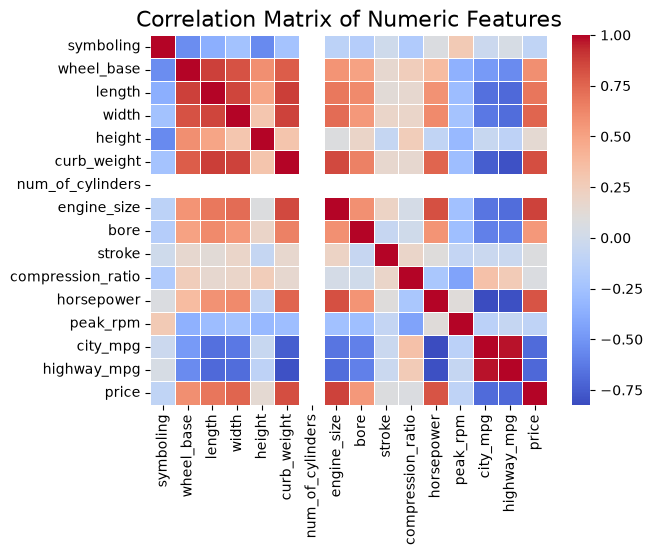

In [71]:
# Correlation matrix

plt.figure()
corr_matrix = df_clean.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title("Correlation Matrix of Numeric Features", fontsize=16)
plt.show()

Comments:


- Strongest positive correlation with price : engine_size, curb_weigth, width. As cars get heavier, wider, and feature larger engines, their market price increases significantly.
- Strongest negative correlation with price : city_mpg, highway_mpg. Higher horsepower and larger engines drastically decrease fuel efficiency.

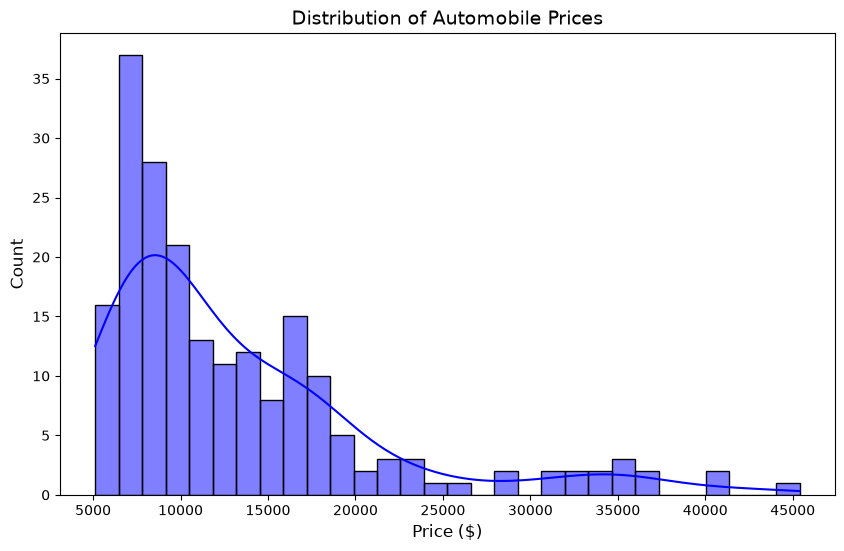

,symboling,make,fuel_type,aspiration,num_of_doors,body_style,drive_wheels,engine_location,wheel_base,length,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
71,1,mercedes-benz,gas,std,two,hardtop,rwd,front,112.0,199.2,...,304,mpfi,3.80,3.35,8.0,184.0,4500.0,14,16,45400
15,0,bmw,gas,std,two,sedan,rwd,front,103.5,193.8,...,209,mpfi,3.62,3.39,8.0,182.0,5400.0,16,22,41315
70,0,mercedes-benz,gas,std,four,sedan,rwd,front,120.9,208.1,...,308,mpfi,3.80,3.35,8.0,184.0,4500.0,14,16,40960


In [72]:
# Price distribution

plt.figure(figsize=(10, 6))
sns.histplot(df_clean['price'], kde=True, color='blue', bins=30)
plt.title("Distribution of Automobile Prices", fontsize=14)
plt.xlabel("Price ($)", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.show()
df_clean.nlargest(3, 'price')

Comments:

- The vast majority of automobiles are concentrated in an affordable price bracket (between $5,000 and $12,000).
- A long right tail indicates the presence of luxury and high-performance sports cars reaching up to $35,000+, which pull the average price up compared to the median.

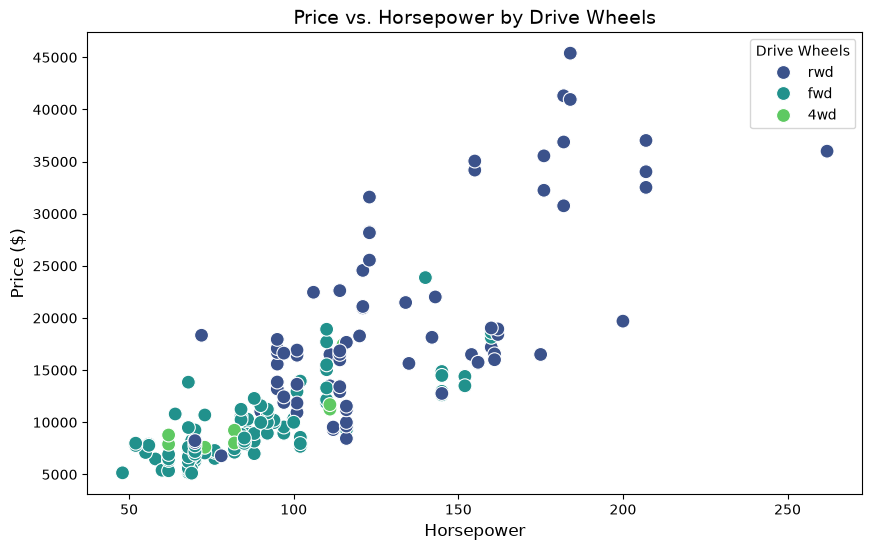

In [73]:
# Price vs Horsepower

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clean, x='horsepower', y='price', hue='drive_wheels', palette='viridis', s=100)
plt.title("Price vs. Horsepower by Drive Wheels", fontsize=14)
plt.xlabel("Horsepower", fontsize=12)
plt.ylabel("Price ($)", fontsize=12)
plt.legend(title="Drive Wheels")
plt.show()

Comments :

- Clear upward trend : as horsepower increases so does the price.
- Rear-wheel drive (rwd) vehicles dominate the higher end of both horsepower and price spectrums. In contrast, front-wheel drive (fwd) cars are heavily clustered in the lower-to-mid horsepower and lower price ranges, representing standard commuter vehicles.

/var/folders/4b/05n7cps562g7sxc_z9yc_tmm0000gn/T/ipykernel_97714/2714443340.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=avg_price_per_make.index, y=avg_price_per_make.values, palette='magma')


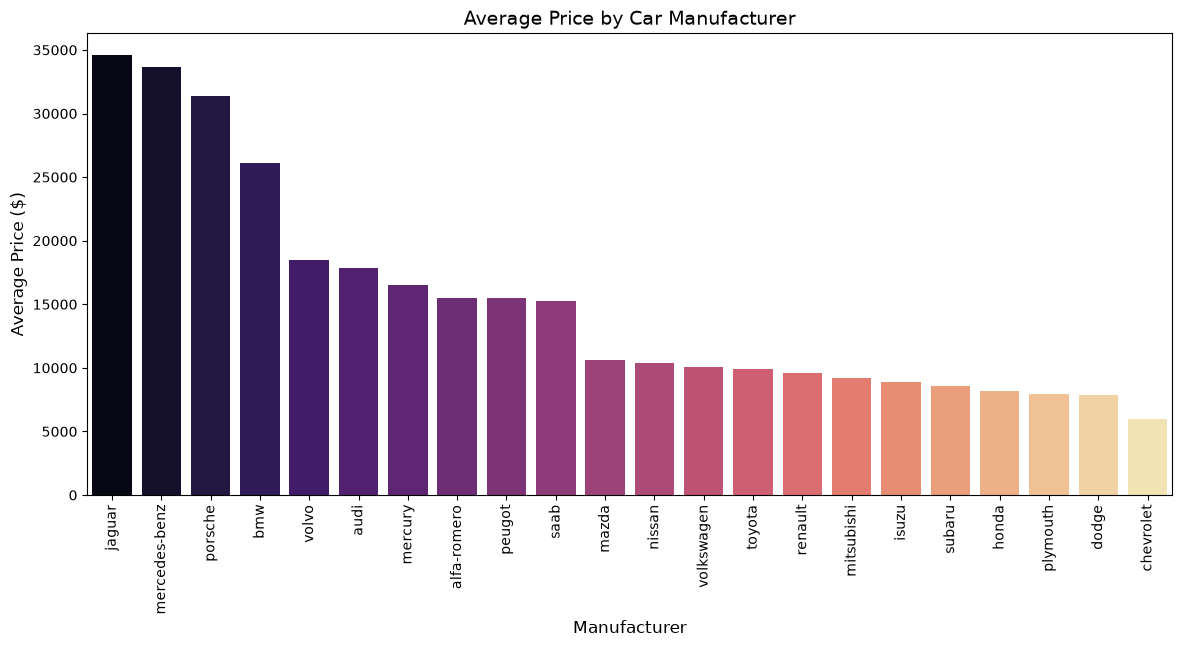

In [74]:
# Average Price by car manufacturer

plt.figure(figsize=(14, 6))

avg_price_per_make = df_clean.groupby('make')['price'].mean().sort_values(ascending=False)

sns.barplot(x=avg_price_per_make.index, y=avg_price_per_make.values, palette='magma')
plt.title("Average Price by Car Manufacturer", fontsize=14)
plt.xlabel("Manufacturer", fontsize=12)
plt.ylabel("Average Price ($)", fontsize=12)
plt.xticks(rotation=90)
plt.show()

Comments :

- Premium and luxury manufacturers like Jaguar, Mercedes-Benz, Porsche, and BMW command the highest average market prices.
- Chevrolet, Dodge, and Subaru sit at the lower end of the average price spectrum.

## Business Insights

  drive_wheels         price  horsepower   city_mpg
0          4wd  10241.000000   87.250000  24.000000
1          fwd   9244.779661   86.250000  28.152542
2          rwd  19795.342105  131.407895  20.605263


/var/folders/4b/05n7cps562g7sxc_z9yc_tmm0000gn/T/ipykernel_97714/1297314456.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='drive_wheels', y='price', palette='Set1')


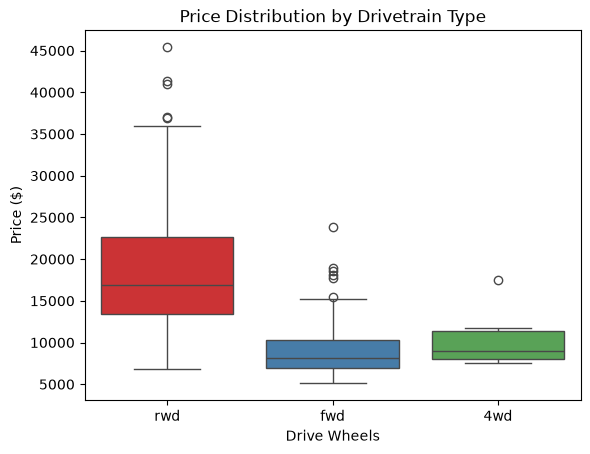

In [75]:
# Price distribution by drive wheels
drivetrain = df_clean.groupby('drive_wheels')[['price', 'horsepower', 'city_mpg']].mean().reset_index()
print(drivetrain)

plt.figure()
sns.boxplot(data=df_clean, x='drive_wheels', y='price', palette='Set1')
plt.title("Price Distribution by Drivetrain Type")
plt.xlabel("Drive Wheels")
plt.ylabel("Price ($)")
plt.show()

Comments :

- Rear-wheel drive (rwd) models show a higher median and maximum price compared to front-wheel drive (fwd) cars, reflecting their presence in sports and luxury area.

  fuel_type         price  highway_mpg  horsepower
0    diesel  15838.150000    34.750000   84.450000
1       gas  12969.752747    30.208791  105.561111


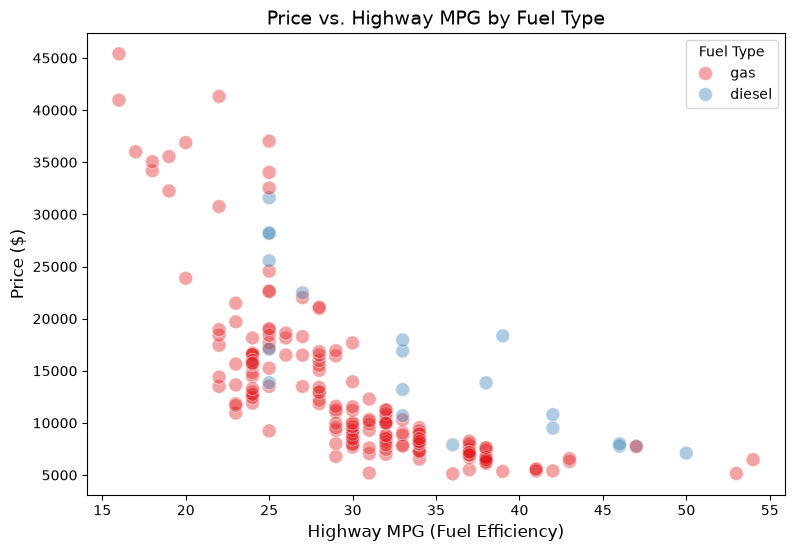

In [76]:
# Fuel type

fuel = df_clean.groupby('fuel_type')[['price', 'highway_mpg', 'horsepower']].mean().reset_index()
print(fuel)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=df_clean, x='highway_mpg', y='price', hue='fuel_type', palette='Set1', s=100, alpha=0.4)
plt.title("Price vs. Highway MPG by Fuel Type", fontsize=14)
plt.xlabel("Highway MPG (Fuel Efficiency)", fontsize=12)
plt.ylabel("Price ($)", fontsize=12)
plt.legend(title="Fuel Type")
plt.show()

Comments :

- Diesel vehicles show lower highway fuel consumption for specialized engine architecture, typically positioned in heavier vehicle classes.

/var/folders/4b/05n7cps562g7sxc_z9yc_tmm0000gn/T/ipykernel_97714/3325575199.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=body_analysis.index, y=body_analysis['price'], palette='coolwarm')


                    price  horsepower
body_style                           
hardtop      22208.500000  142.250000
convertible  21890.500000  131.666667
sedan        14545.705263  103.915789
wagon        12371.960000   97.750000
hatchback     9957.441176   97.671642


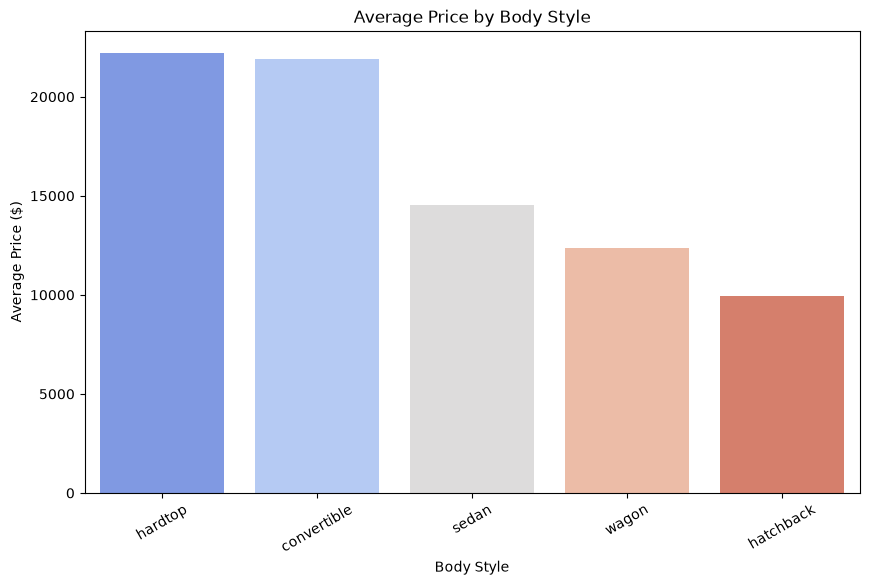

In [77]:
# Body Style

body_analysis = df_clean.groupby('body_style')[['price', 'horsepower']].mean().sort_values(by='price', ascending=False)
print(body_analysis)

plt.figure(figsize=(10, 6))
sns.barplot(x=body_analysis.index, y=body_analysis['price'], palette='coolwarm')
plt.title("Average Price by Body Style")
plt.xlabel("Body Style")
plt.ylabel("Average Price ($)")
plt.xticks(rotation=30)
plt.show()

Comments :

- Convertible and hardtop body styles generally command higher average prices despite lower production volume, driven by niche market appeal.

## Machine Learning and Predictive Modeling

In [85]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

In [88]:
# Predict a car's price using a few features

features = ['horsepower', 'curb_weight', 'engine_size', 'highway_mpg', 'width']

# Cleaning data before the model
df_ml = df_clean[features + ['price']].dropna()

X = df_ml[features] # predictive features
y = df_ml['price'] # target variable

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) # 20% test data, 80% train data

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (160, 5)
Testing set shape: (40, 5)


In [89]:
# Linear Regression model

model = LinearRegression()
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluation metrics
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"Model R² Score: {r2:.4f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:.2f}")


Model R² Score: 0.7689
Root Mean Squared Error (RMSE): $5371.51


Comments :

- Explained Variance ($R^2$): A moderately high score for $R^2$ confirms that mechanical specs and vehicle size capture a substantial share of pricing logic, while the remaining variance likely depends on brand equity, trim level, or non-linear effects.
- Prediction Error (RMSE): Reporting RMSE alongside $R^2$ gives stakeholders a concrete sense of dollar error magnitude rather than a dimensionless score alone.

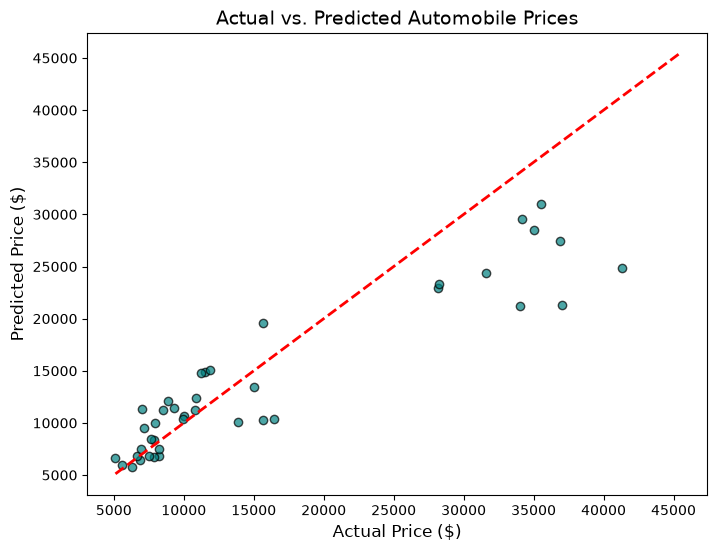

In [90]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='teal', alpha=0.7, edgecolors='k')
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--', lw=2)
plt.title("Actual vs. Predicted Automobile Prices", fontsize=14)
plt.xlabel("Actual Price ($)", fontsize=12)
plt.ylabel("Predicted Price ($)", fontsize=12)
plt.show()

Comments :

- Points clustering close to the red dashed 45-degree reference line indicate accurate predictions, whereas vertical spread shows where the model over- or under-estimates price.

- Deviations tend to widen for higher-priced vehicles, suggesting that a simple linear model on basic specs is less flexible for luxury/specialty cars.